In [2]:
import pandas as pd
web_url = "https://reports-public.ieso.ca/public/Demand/PUB_Demand_2025.csv"
df = pd.read_csv(web_url, skiprows=3)
df.head()

,Date,Hour,Market Demand,Ontario Demand
0,2025-01-01,1,17247,13887
1,2025-01-01,2,17355,13722
2,2025-01-01,3,17638,13688
3,2025-01-01,4,17065,13613
4,2025-01-01,5,17498,13593


In [3]:
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8759 entries, 0 to 8758
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   Date            8759 non-null   object
 1   Hour            8759 non-null   int64 
 2   Market Demand   8759 non-null   int64 
 3   Ontario Demand  8759 non-null   int64 
dtypes: int64(3), object(1)
memory usage: 273.8+ KB


,Hour,Market Demand,Ontario Demand
count,8759.000000,8759.000000,8759.000000
mean,12.501313,18896.128097,16621.474598
std,6.921886,2299.611752,2455.815560
min,1.000000,13055.000000,11536.000000
25%,7.000000,17146.500000,14866.000000
50%,13.000000,18638.000000,16410.000000
75%,18.500000,20464.000000,18241.500000
max,24.000000,26714.000000,24862.000000


In [4]:
df["Ontario Demand"].describe()

count     8759.000000
mean     16621.474598
std       2455.815560
min      11536.000000
25%      14866.000000
50%      16410.000000
75%      18241.500000
max      24862.000000
Name: Ontario Demand, dtype: float64

Matplotlib is building the font cache; this may take a moment.


<Axes: title={'center': 'Ontario Hourly Demand, 2025'}, xlabel='Datetime'>

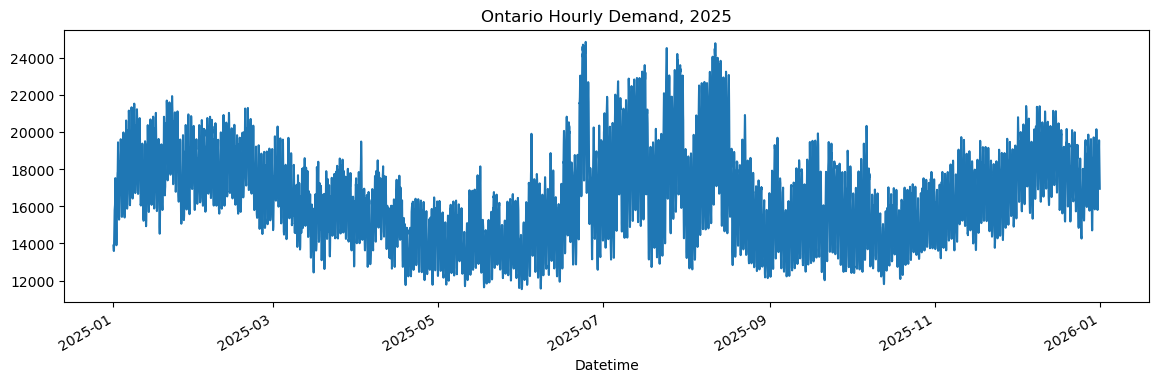

In [5]:
df["Datetime"] = pd.to_datetime(df["Date"]) + pd.to_timedelta(df["Hour"] - 1, unit="h")
df = df.set_index("Datetime")

df["Ontario Demand"].plot(figsize=(14, 4), title="Ontario Hourly Demand, 2025")

<Axes: title={'center': 'One week, January 2025'}, xlabel='Datetime'>

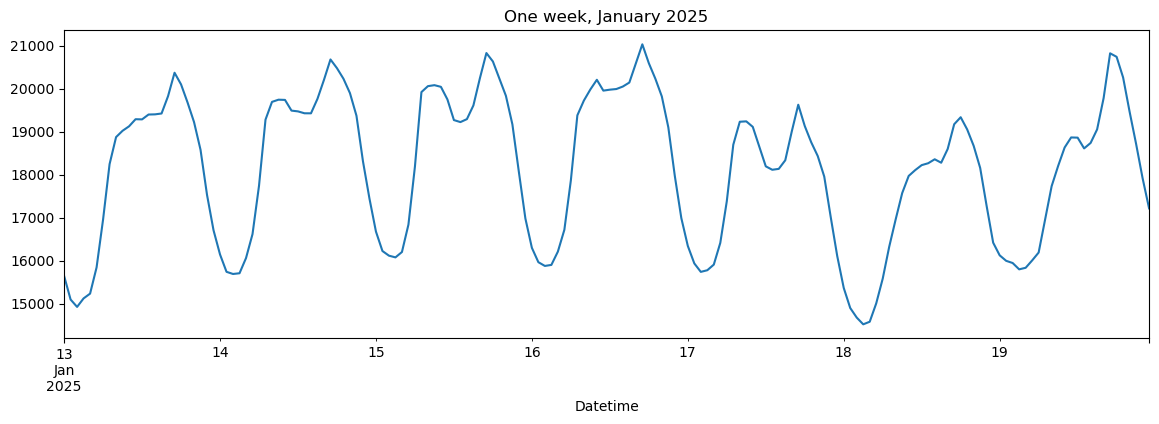

In [6]:
df.loc["2025-01-13":"2025-01-19", "Ontario Demand"].plot(figsize=(14, 4), title="One week, January 2025")

In [13]:
df.index = pd.to_datetime(df.index)
df.index.dtype     # should now say: datetime64[ns]

dtype('<M8[ns]')

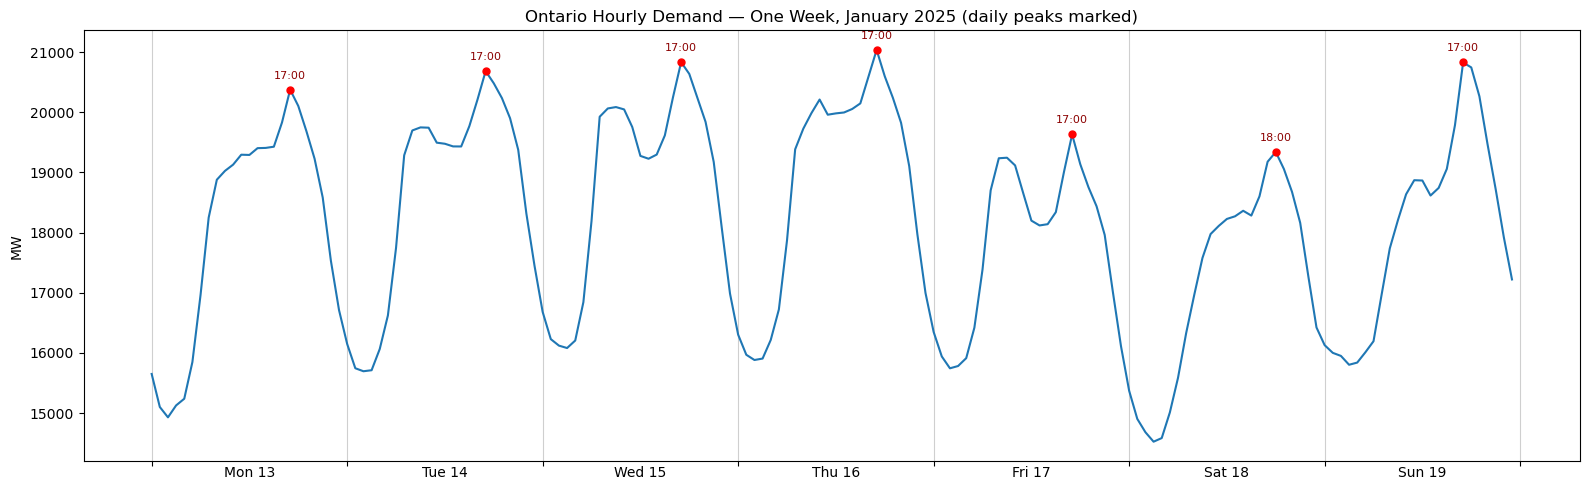

In [17]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

week = raw.loc["2025-01-13":"2025-01-19", "Ontario Demand"]

fig, ax = plt.subplots(figsize=(16, 5))
ax.plot(week.index, week.values)

# Boundaries: gridline at each midnight, but NO label there
ax.xaxis.set_major_locator(mdates.DayLocator())
ax.xaxis.set_major_formatter(plt.NullFormatter())
ax.grid(which="major", axis="x", alpha=0.6)

# Labels: day name centered at NOON of each day
ax.xaxis.set_minor_locator(mdates.HourLocator(byhour=[12]))
ax.xaxis.set_minor_formatter(mdates.DateFormatter("%a %d"))
ax.tick_params(axis="x", which="minor", length=0, labelsize=10)   # length=0: label without a tick mark

# Mark each day's peak with a dot + hour annotation
daily_peaks = week.groupby(week.index.date).idxmax()
for ts in daily_peaks:
    ax.plot(ts, week[ts], "ro", markersize=5)
    ax.annotate(f"{ts:%H}:00", (ts, week[ts]), textcoords="offset points",
                xytext=(0, 8), ha="center", fontsize=8, color="darkred")

ax.set_title("Ontario Hourly Demand — One Week, January 2025 (daily peaks marked)")
ax.set_ylabel("MW")
plt.tight_layout()
plt.show()

<Axes: title={'center': 'January 2025: Mean Demand by Hour of Day'}, xlabel='Datetime', ylabel='MW'>

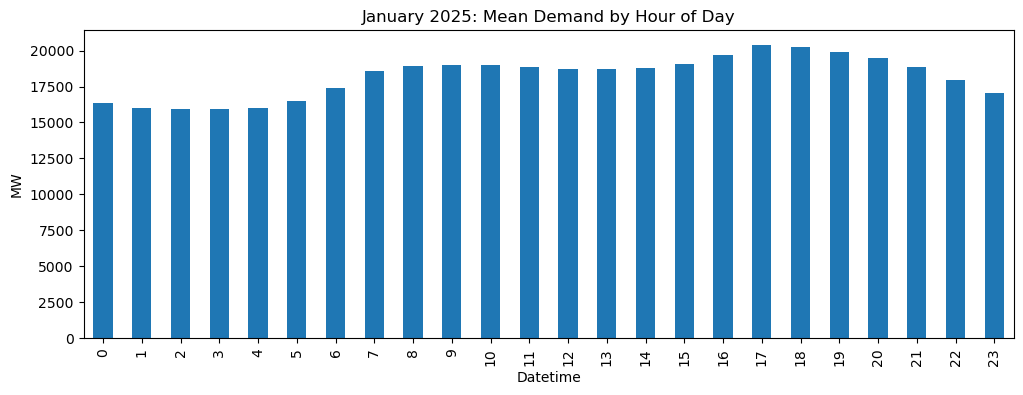

In [16]:
raw.loc["2025-01", "Ontario Demand"].groupby(raw.loc["2025-01"].index.hour).mean().plot(kind="bar", figsize=(12,4), title="January 2025: Mean Demand by Hour of Day", ylabel="MW")